Dental Disease Detection — Dataset Audit

In [3]:
# Imports and configuration
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

# Project root is one level above the notebooks/ folder
PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()

CLASSIFICATION_DIR = (
    PROJECT_ROOT / "data" / "raw" / "primary"
    / "Dental OPG XRAY Dataset" / "Dental OPG (Classification)"
)

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

print("Classification directory:", CLASSIFICATION_DIR)
print("Exists:", CLASSIFICATION_DIR.exists())

Classification directory: /Users/kmohsin/Documents/GitHub/Computer-Vision-Dental-Disease-Detection/data/raw/primary/Dental OPG XRAY Dataset/Dental OPG (Classification)
Exists: True


## Classification Dataset: Class Distribution

Count the number of X-ray images in each dental condition category and visualize class imbalance.

In [8]:
# Count classification images per class
class_counts = []

for class_folder in sorted(CLASSIFICATION_DIR.iterdir()):
    if not class_folder.is_dir():
        continue

    images = [
        p for p in class_folder.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    class_counts.append({
        "Class": class_folder.name,
        "Image Count": len(images)
    })

df_counts = pd.DataFrame(class_counts)

df_counts = df_counts.sort_values(
    "Image Count",
    ascending=False
).reset_index(drop=True)

display(df_counts)

print("Total images:", df_counts["Image Count"].sum())

,Class,Image Count
0,Healthy Teeth,223
1,Caries,119
2,Impacted teeth,87
3,BDC-BDR,52
4,Infection,23
5,Fractured Teeth,13


Total images: 517


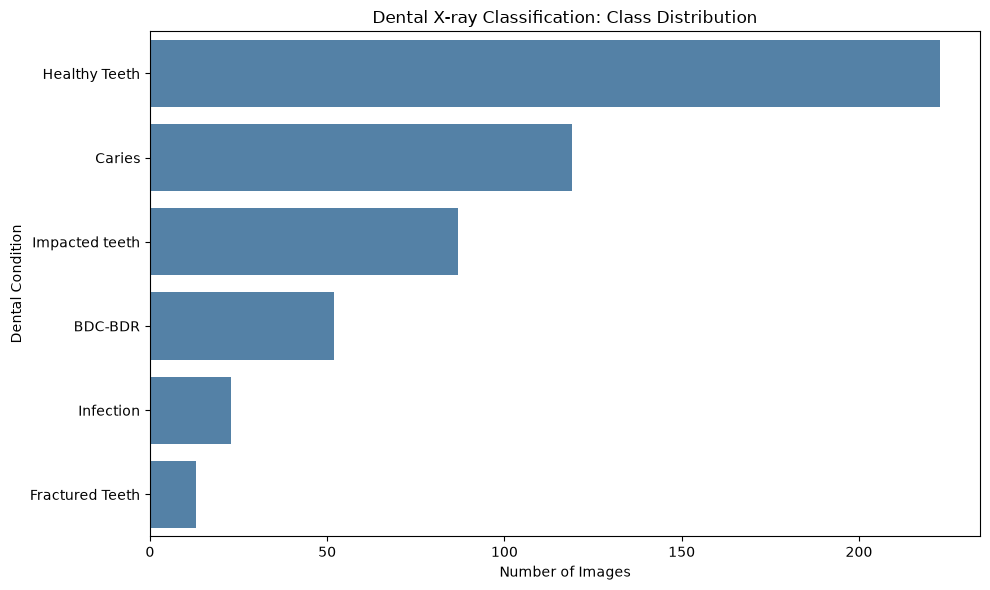

In [9]:
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.barplot(
    data=df_counts,
    x="Image Count",
    y="Class",
    color="steelblue"
)

plt.title("Dental X-ray Classification: Class Distribution")
plt.xlabel("Number of Images")
plt.ylabel("Dental Condition")

plt.tight_layout()
plt.show()

## Image Dimensions and Formats

In this section, we examine the original image resolutions,
color modes, and file formats.

This will help determine the preprocessing required before
training our classification model.

In [4]:
# Store image information
image_info = []
corrupt_images = []

for class_folder in sorted(CLASSIFICATION_DIR.iterdir()):

    if not class_folder.is_dir():
        continue

    for image_path in class_folder.rglob("*"):

        if not image_path.is_file():
            continue

        if image_path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue

        try:
            with Image.open(image_path) as img:
                image_info.append({
                    "Class": class_folder.name,
                    "Filename": image_path.name,
                    "Width": img.width,
                    "Height": img.height,
                    "Format": img.format,
                    "Color Mode": img.mode
                })

        except Exception as e:
            corrupt_images.append({
                "File": str(image_path),
                "Error": str(e)
            })

df_images = pd.DataFrame(image_info)

print("Successfully opened images:", len(df_images))
print("Images that could not be opened:", len(corrupt_images))

display(df_images.head(10))

Successfully opened images: 517
Images that could not be opened: 0


,Class,Filename,Width,Height,Format,Color Mode
0,BDC-BDR,77.jpg,1185,521,JPEG,L
1,BDC-BDR,228.jpg,1182,687,JPEG,L
2,BDC-BDR,214.jpg,1162,552,JPEG,L
3,BDC-BDR,215.jpg,1184,662,JPEG,L
4,BDC-BDR,229.jpg,1009,506,JPEG,L
5,BDC-BDR,177.jpg,1280,698,JPEG,L
6,BDC-BDR,62.jpg,1437,727,JPEG,L
7,BDC-BDR,149.jpg,1078,462,JPEG,L
8,BDC-BDR,207.jpg,838,415,JPEG,L
9,BDC-BDR,159.jpg,1183,648,JPEG,L


In [5]:
print("IMAGE DIMENSION STATISTICS")

display(df_images[["Width", "Height"]].describe())

print("\nIMAGE FORMATS")
display(df_images["Format"].value_counts())

print("\nCOLOR MODES")
display(df_images["Color Mode"].value_counts())

print("\nMOST COMMON IMAGE DIMENSIONS")
display(
    df_images.groupby(["Width", "Height"])
    .size()
    .sort_values(ascending=False)
    .head(10)
)

IMAGE DIMENSION STATISTICS


,Width,Height
count,517.000000,517.000000
mean,1205.874275,610.847195
std,262.791318,143.214812
min,497.000000,259.000000
25%,1058.000000,511.000000
50%,1176.000000,593.000000
75%,1298.000000,678.000000
max,1988.000000,1260.000000



IMAGE FORMATS


Format
JPEG    517
Name: count, dtype: int64


COLOR MODES


Color Mode
L      474
RGB     43
Name: count, dtype: int64


MOST COMMON IMAGE DIMENSIONS


Width  Height
1203   642       8
1437   727       5
1157   591       5
1437   613       5
1280   698       4
1155   584       4
1372   583       4
1092   484       4
1088   452       4
1189   640       4
dtype: int64

## Sample Image Visualization

We will display representative dental X-rays from each
classification category to understand the visual differences
between conditions.

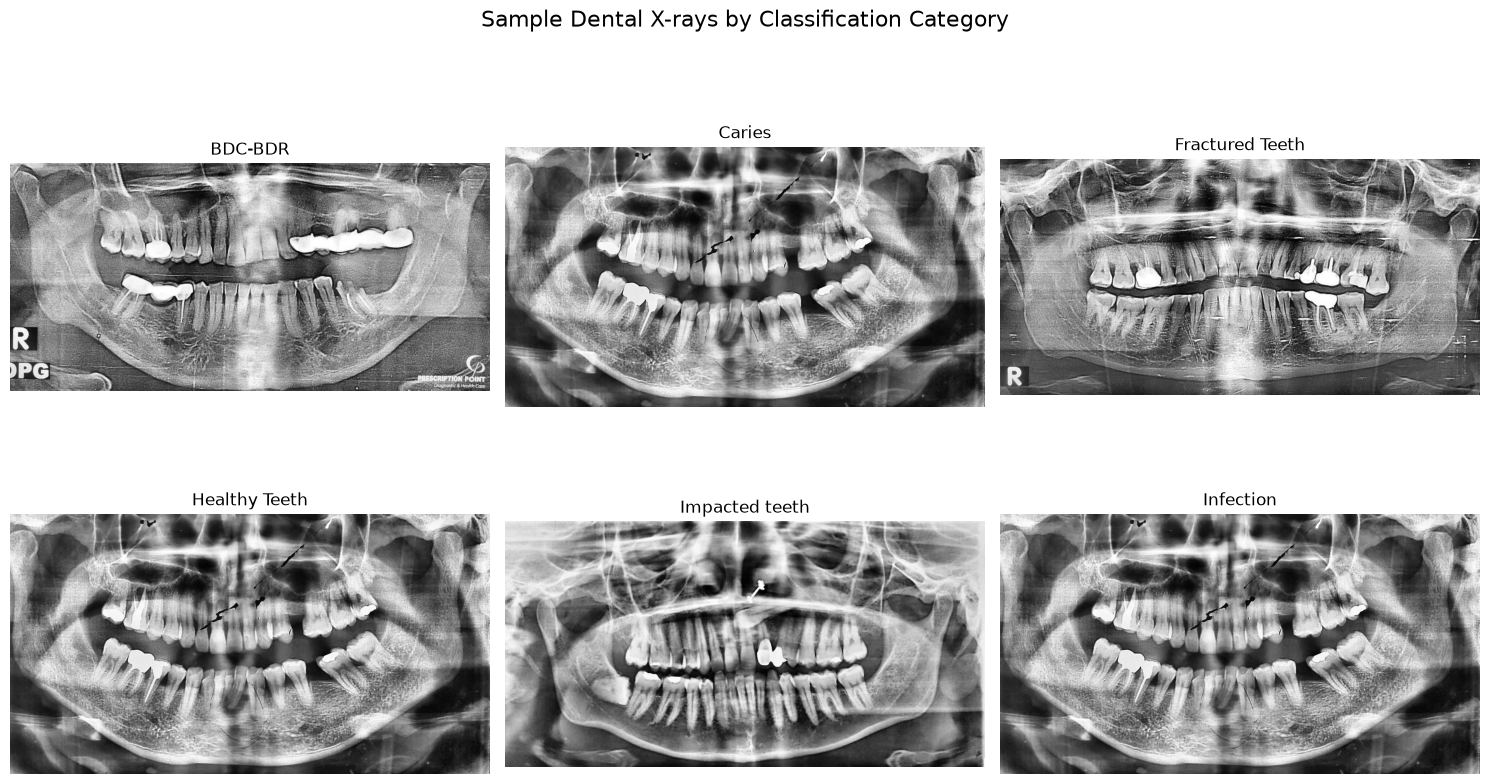

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

axes = axes.flatten()

class_folders = sorted([
    folder for folder in CLASSIFICATION_DIR.iterdir()
    if folder.is_dir()
])

for i, class_folder in enumerate(class_folders):

    images = [
        p for p in class_folder.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    if images:
        image_path = sorted(images)[0]

        with Image.open(image_path) as img:
            axes[i].imshow(img.convert("L"), cmap="gray")

        axes[i].set_title(class_folder.name)
        axes[i].axis("off")

plt.suptitle("Sample Dental X-rays by Classification Category", fontsize=16)
plt.tight_layout()
plt.show()

In [7]:
if len(corrupt_images) == 0:
    print("No unreadable image files detected during opening.")
else:
    print(f"Found {len(corrupt_images)} unreadable images.")
    display(pd.DataFrame(corrupt_images))

No unreadable image files detected during opening.
